In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from rasterio.crs import CRS
from pyproj import Proj, transform, Transformer
import seaborn as sns
from matplotlib import pyplot as plt
from rasterio.features import rasterize
from affine import Affine
from pathlib import Path

load global map

In [2]:
world_map = gpd.read_file('../data/gadm-world/world-map.shp')
China_provinces = gpd.read_file('../data/China-map/省.shp')

change the projection

In [3]:
world_map_eck4 = world_map.to_crs("ESRI:54012")
China_provinces_eck4 = China_provinces.to_crs("ESRI:54012")

load the merged countries list

In [4]:
df_cement_production = pd.read_csv("../data/production-142.csv", index_col=0)
economies_142 = df_cement_production.columns.tolist()

In [5]:
merged_countries = pd.read_excel("../data/contents.xlsx", sheet_name='merged_countries')

mark the countries in map

In [6]:
parents = merged_countries['parent'].unique().tolist()
others = [country for country in economies_142 if country not in parents]

In [7]:
world_map_eck4['economies_142'] = np.nan

In [15]:
world_map_eck4[world_map_eck4['COUNTRY'] == 'South Sudan']

,GID_0,COUNTRY,geometry,economies_142
183,SSD,South Sudan,"POLYGON ((2797726.006 577602.093, 2797790.647 ...",NaN


In [9]:
for country in others:
    try:
        the_idx = world_map_eck4[world_map_eck4['GID_0'] == country].index.values[0] 
        world_map_eck4.loc[the_idx, 'economies_142'] = country 
    except:
        print(country)

for country in parents:
    childs = merged_countries[merged_countries['parent'] == country]['child'].values.tolist() 
    for child in childs:
        the_idx = world_map_eck4[world_map_eck4['GID_0'] == child].index.values[0] 
        world_map_eck4.loc[the_idx, 'economies_142'] = country 

HKG
MAC


C:\Users\Administrator\AppData\Local\Temp\ipykernel_104748\676829457.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'AFG' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  world_map_eck4.loc[the_idx, 'economies_142'] = country


In [10]:
economies_142_map = world_map_eck4[~world_map_eck4['economies_142'].isna()]
economies_142_map.reset_index(drop=True, inplace=True)

In [11]:
economies_142_map

,GID_0,COUNTRY,geometry,economies_142
0,IRN,Iran,"MULTIPOLYGON (((5561606.523 3254895.679, 55616...",IRN
1,UGA,Uganda,"POLYGON ((2811485.288 -194669.364, 2811461.46 ...",UGA
2,SLE,Sierra Leone,"MULTIPOLYGON (((-1089022.845 920725.415, -1089...",SLE
3,BFA,Burkina Faso,"POLYGON ((-390450.536 1285188.056, -390708.481...",BFA
4,SRB,Serbia,"MULTIPOLYGON (((1853645.84 5264921.471, 185201...",YUG
...,...,...,...,...
159,JAM,Jamaica,"MULTIPOLYGON (((-7183644.546 2223763.693, -718...",JAM
160,CAN,Canada,"MULTIPOLYGON (((-9967750.104 5901254.645, -996...",CAN
161,PNG,Papua New Guinea,"MULTIPOLYGON (((14312868.579 -1525150.672, 143...",PNG
162,PHL,Philippines,"MULTIPOLYGON (((11766134.705 707327.318, 11766...",PHL


In [12]:
economies_142_map.loc[164, 'GID_0'] = 'HKG'
economies_142_map.loc[164, 'COUNTRY'] = 'Hong Kong'
economies_142_map.loc[164, 'economies_142'] = 'HKG'
economies_142_map.loc[164, 'geometry'] = China_provinces_eck4[China_provinces_eck4['省'] == '香港特别行政区'].geometry.values[0]

economies_142_map.loc[165, 'GID_0'] = 'MAC'
economies_142_map.loc[165, 'COUNTRY'] = 'Macao'
economies_142_map.loc[165, 'economies_142'] = 'MAC'
economies_142_map.loc[165, 'geometry'] = China_provinces_eck4[China_provinces_eck4['省'] == '澳门特别行政区'].geometry.values[0]

C:\Users\Administrator\AppData\Local\Temp\ipykernel_104748\2445935091.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  economies_142_map.loc[164, 'GID_0'] = 'HKG'


define the transform

In [12]:
wgs84 = CRS.from_epsg(4326)
eckert4 = CRS.from_proj4("+proj=eck4 +lon_0=0 +x_0=0 +y_0=0 +datum=WGS84 +units=m")

In [13]:
transformer_eckert4 = Transformer.from_crs(wgs84, eckert4, always_xy=True)

In [14]:
_, y_north = transformer_eckert4.transform(0, 90) 
x_east, _ = transformer_eckert4.transform(180, 0) 

shape_eckert4_1km = (int((y_north // 1e3 + 1) * 2), int((x_east // 1e3 + 1) * 2))
shape_eckert4_10km = (int((y_north // 1e4 + 1) * 2), int((x_east // 1e4 + 1) * 2))
shape_eckert4_30km = (int((y_north // 3e4 + 1) * 2), int((x_east // 3e4 + 1) * 2))
shape_eckert4_50km = (int((y_north // 5e4 + 1) * 2), int((x_east // 5e4 + 1) * 2))
shape_eckert4_100km = (int((y_north // 1e5 + 1) * 2), int((x_east // 1e5 + 1) * 2))

print(shape_eckert4_1km)
print(shape_eckert4_10km)
print(shape_eckert4_30km)
print(shape_eckert4_50km)
print(shape_eckert4_100km)

xmin_eckert4_1km, ymax_eckert4_1km = - (x_east // 1e3 + 1) * 1e3, (y_north // 1e3 + 1) * 1e3
xmin_eckert4_10km, ymax_eckert4_10km = - (x_east // 1e4 + 1) * 1e4, (y_north // 1e4 + 1) * 1e4 
xmin_eckert4_30km, ymax_eckert4_30km = - (x_east // 3e4 + 1) * 3e4, (y_north // 3e4 + 1) * 3e4 
xmin_eckert4_50km, ymax_eckert4_50km = - (x_east // 5e4 + 1) * 5e4, (y_north // 5e4 + 1) * 5e4
xmin_eckert4_100km, ymax_eckert4_100km = - (x_east // 1e5 + 1) * 1e5, (y_north // 1e5 + 1) * 1e5 

transform_eckert4_1km = Affine(1e3, 0, xmin_eckert4_1km, 0, -1e3, ymax_eckert4_1km)
transform_eckert4_10km = Affine(1e4, 0, xmin_eckert4_10km, 0, -1e4, ymax_eckert4_10km)
transform_eckert4_30km = Affine(3e4, 0, xmin_eckert4_30km, 0, -3e4, ymax_eckert4_30km)
transform_eckert4_50km = Affine(5e4, 0, xmin_eckert4_50km, 0, -5e4, ymax_eckert4_50km)
transform_eckert4_100km = Affine(1e5, 0, xmin_eckert4_100km, 0, -1e5, ymax_eckert4_100km)
print(transform_eckert4_1km)
print(transform_eckert4_10km)
print(transform_eckert4_30km)
print(transform_eckert4_50km)
print(transform_eckert4_100km)

(16922, 33844)
(1694, 3386)
(566, 1130)
(340, 678)
(170, 340)
| 1000.00, 0.00,-16922000.00|
| 0.00,-1000.00, 8461000.00|
| 0.00, 0.00, 1.00|
| 10000.00, 0.00,-16930000.00|
| 0.00,-10000.00, 8470000.00|
| 0.00, 0.00, 1.00|
| 30000.00, 0.00,-16950000.00|
| 0.00,-30000.00, 8490000.00|
| 0.00, 0.00, 1.00|
| 50000.00, 0.00,-16950000.00|
| 0.00,-50000.00, 8500000.00|
| 0.00, 0.00, 1.00|
| 100000.00, 0.00,-17000000.00|
| 0.00,-100000.00, 8500000.00|
| 0.00, 0.00, 1.00|


create pseudo-codes for easy country indexing

In [15]:
economies_142_map

,GID_0,COUNTRY,geometry,economies_142
0,IRN,Iran,"MULTIPOLYGON (((5561606.523 3254895.679, 55616...",IRN
1,UGA,Uganda,"POLYGON ((2811485.288 -194669.364, 2811461.46 ...",UGA
2,SLE,Sierra Leone,"MULTIPOLYGON (((-1089022.845 920725.415, -1089...",SLE
3,BFA,Burkina Faso,"POLYGON ((-390450.536 1285188.056, -390708.481...",BFA
4,SRB,Serbia,"MULTIPOLYGON (((1853645.84 5264921.471, 185201...",YUG
...,...,...,...,...
161,PNG,Papua New Guinea,"MULTIPOLYGON (((14312868.579 -1525150.672, 143...",PNG
162,PHL,Philippines,"MULTIPOLYGON (((11766134.705 707327.318, 11766...",PHL
163,ARM,Armenia,"MULTIPOLYGON (((3893704.319 4991201.514, 38942...",SUN
164,HKG,Hong Kong,"MULTIPOLYGON (((10390612.512 2876530.363, 1039...",HKG


In [16]:
df_country_pseudo_values = pd.DataFrame([], columns=['value', 'economies_142', 'country', 'full name'])
df_country_pseudo_values['country'] = economies_142_map['GID_0']
df_country_pseudo_values['full name'] = economies_142_map['COUNTRY']

In [17]:
for i, economy in enumerate(economies_142):
    # print(i+1, country)
    the_idx = economies_142_map[economies_142_map['economies_142'] == economy].index.tolist()
    df_country_pseudo_values.loc[the_idx, 'economies_142'] = economy
    df_country_pseudo_values.loc[the_idx, 'value'] = i+1

In [18]:
df_country_pseudo_values

,value,economies_142,country,full name
0,67,IRN,IRN,Iran
1,134,UGA,UGA,Uganda
2,118,SLE,SLE,Sierra Leone
3,21,BFA,BFA,Burkina Faso
4,16,YUG,SRB,Serbia
...,...,...,...,...
161,102,PNG,PNG,Papua New Guinea
162,105,PHL,PHL,Philippines
163,6,SUN,ARM,Armenia
164,60,HKG,HKG,Hong Kong


In [ ]:
df_country_pseudo_values.to_csv('../results/pseudo-codes-economies-142.csv', index=False)

rasterize map to EckertIV grid

In [19]:
economies_shapes_eck4 = [(a_shape, a_value) for a_shape, a_value in zip(economies_142_map.geometry, df_country_pseudo_values['value'])]

In [34]:
economies_raster_eck4_1km = rasterize(
    shapes=economies_shapes_eck4, 
    out_shape=shape_eckert4_1km, 
    fill=0, 
    transform=transform_eckert4_1km)

In [35]:
economies_raster_eck4_10km = rasterize(
    shapes=economies_shapes_eck4, 
    out_shape=shape_eckert4_10km, 
    fill=0, 
    transform=transform_eckert4_10km)

In [20]:
economies_raster_eck4_50km = rasterize(
    shapes=economies_shapes_eck4, 
    out_shape=shape_eckert4_50km, 
    fill=0, 
    transform=transform_eckert4_50km)

display global tiff files at different resolution

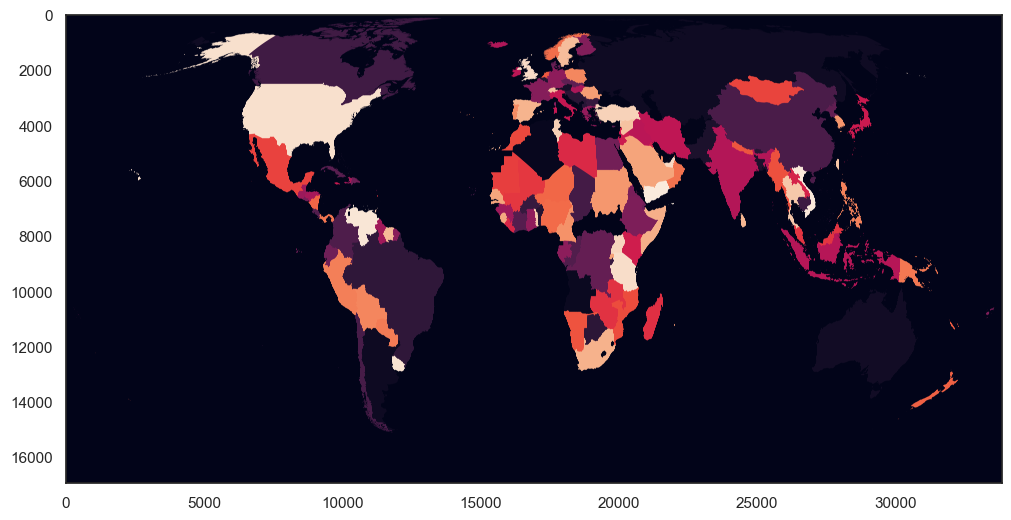

In [37]:
sns.set_theme(style="white")

fig = plt.figure(figsize=(10, 8), constrained_layout=True)
ax1 = plt.subplot(111)
ax1.imshow(economies_raster_eck4_1km)

plt.show()

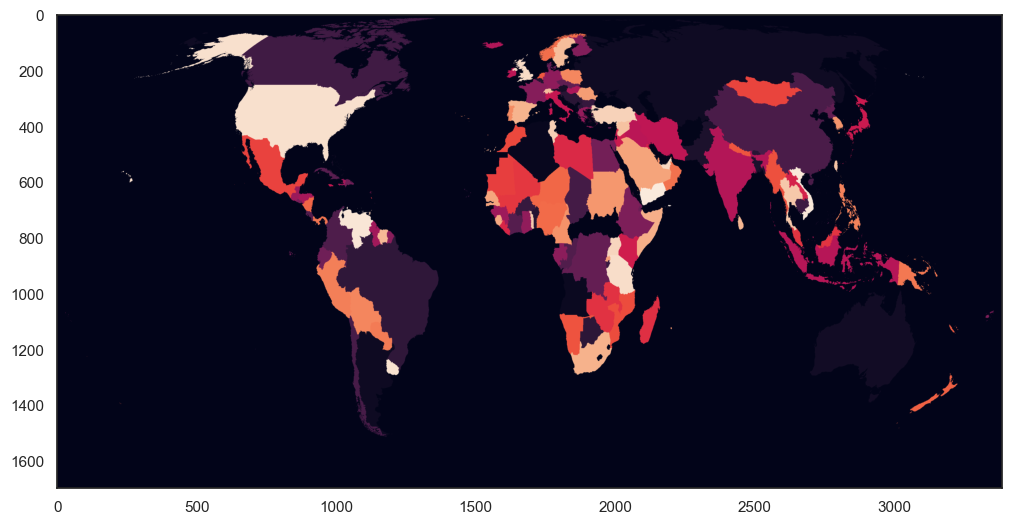

In [38]:
sns.set_theme(style="white")

fig = plt.figure(figsize=(10, 8), constrained_layout=True)
ax1 = plt.subplot(111)
ax1.imshow(economies_raster_eck4_10km)

plt.show()

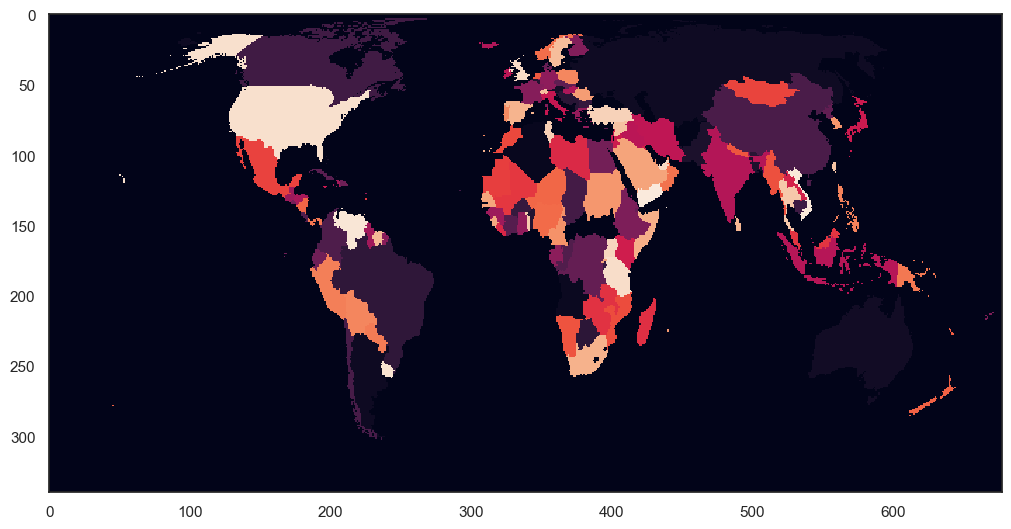

In [22]:
sns.set_theme(style="white")

fig = plt.figure(figsize=(10, 8), constrained_layout=True)
ax1 = plt.subplot(111)
ax1.imshow(economies_raster_eck4_50km, interpolation='nearest')

plt.show()

export tiff files

In [ ]:
Path(r'../results/economy-rasters').mkdir(parents=True, exist_ok=True)

In [ ]:
with rio.open(
    r'../results/economy-rasters/economy-raster-eck4-1km.tif',
    'w',
    driver='GTiff',
    height=economies_raster_eck4_1km.shape[0],
    width=economies_raster_eck4_1km.shape[1],
    count=1,
    dtype=np.uint8, 
    crs='ESRI:54012',
    transform=transform_eckert4_1km,
    compress='lzw',
) as dst:
    dst.write(economies_raster_eck4_1km, 1)

In [ ]:
with rio.open(
    r'../results/economy-rasters/economy-raster-eck4-10km.tif',
    'w',
    driver='GTiff',
    height=economies_raster_eck4_10km.shape[0],
    width=economies_raster_eck4_10km.shape[1],
    count=1,
    dtype=np.uint8, 
    crs='ESRI:54012',
    transform=transform_eckert4_10km,
    compress='lzw',
) as dst:
    dst.write(economies_raster_eck4_10km, 1)

In [23]:
with rio.open(
    r'../results/economy-rasters/economy-raster-eck4-50km.tif',
    'w',
    driver='GTiff',
    height=economies_raster_eck4_50km.shape[0],
    width=economies_raster_eck4_50km.shape[1],
    count=1,
    dtype=np.uint8, 
    crs='ESRI:54012',
    transform=transform_eckert4_50km,
    compress='lzw',
) as dst:
    dst.write(economies_raster_eck4_50km, 1)